# Module 8 — Derivatives: run the whole module

**How to use:**
- **Run all** to run the full module in order, or run a single cell to run one step.
- Each cell runs one notebook in full and shows all its charts and main tables here; the notebook itself shows every table.
- Every notebook also runs on its own: open it from `notebooks/` and run all.

**Order matters:** Task 2 reads the files Task 1 saves in `outputs/task1/`.

**Final output:** `outputs/FINAL_M8_module_output.xlsx` (last cell).

## Setup
Moves into the module folder so the paths below work, both locally and in Google Colab.
- **Colab:** upload the whole unzipped project folder (any name) to Google Drive; the cell below finds it. Then run all cells.

In [1]:
import os
import sys
from pathlib import Path

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]
os.chdir(PROJECT_ROOT / "module_08_derivatives")                  # the paths below start from the module folder
print("Working folder:", Path.cwd().name)

Working folder: module_08_derivatives


## 0. Data check
Is `nova_options.csv` complete and clean? Rows, missing values, calls vs puts, stocks, ranges, and the average market − BS gap.

In [2]:
%run helpers/m08_data.py

rows: 10000
missing_values: 0
option_types: {'Put': 5055, 'Call': 4945}
underlyings: 15
maturity_years_range: (0.03, 2.0)
volatility_range: (0.08, 0.536)
non_positive_prices: 0
mean_abs_gap_market_vs_given_BS: 5.84


## 1. Task 1 — Black-Scholes benchmark
Runs `notebooks/m08_task1_bs_benchmark.ipynb` (about 1 minute):
- explores the 10,000 options (EDA);
- calculates the Black-Scholes price and checks it against the file;
- compares it with the market price in ₹ and %, and tests where it misses;
- flags impossible market prices; works out the Greeks and the book's risk in ₹;
- saves `outputs/task1/FINAL_M8_T1_bs_benchmark.csv` for Task 2.

rows                                10000
missing_values                      0
option_types                        {'Put': 5055, 'Call': 4945}
underlyings                         15
maturity_years_range                (0.03, 2.0)
volatility_range                    (0.08, 0.536)
non_positive_prices                 0
mean_abs_gap_market_vs_given_BS     5.84
Pricing date implied by expiry − time to maturity: 2026-08-31 to 2026-09-01 → every option is priced on the same day
Ranges of each input:


,min,5%,50%,95%,max
Spot (₹),100.590,267.222,1787.605,3328.286,3499.600
Strike (₹),78.350,256.355,1753.065,3514.525,4348.870
In the money by (share),-0.250,-0.202,-0.005,0.247,0.333
Time to maturity (years),0.030,0.127,1.000,1.905,2.000
Volatility (a year),0.080,0.109,0.239,0.370,0.536
Interest rate (a year),0.034,0.052,0.065,0.078,0.099
Market price (₹),0.010,2.249,123.620,617.259,1245.560


What the book holds:


,Group,Breakdown,Options,Average market price (₹),"Total market value (₹ lakh, one unit each)",Share of options
0,Call,Option Type,4945,248.36,12.28,0.49
1,Put,Option Type,5055,140.73,7.11,0.51
2,Far out of the money (< −10%),Moneyness band,2931,66.51,1.95,0.29
3,Out of the money (−10% to −2%),Moneyness band,1740,117.81,2.05,0.17
4,At the money (±2%),Moneyness band,832,169.30,1.41,0.08
5,In the money (2% to 10%),Moneyness band,1495,214.89,3.21,0.15
6,Far in the money (> 10%),Moneyness band,3002,358.93,10.78,0.30
7,Under 3 months,Maturity band,1154,118.26,1.36,0.12
8,3–6 months,Maturity band,1198,146.23,1.75,0.12
9,6–12 months,Maturity band,2647,176.92,4.68,0.26


By stock:


,Options,Calls,Typical spot (₹),Typical volatility,Total market value (₹ lakh)
Underlying,,,,,
AXISBANK,657,333,1812.63,0.24,1.29
BHARTIARTL,665,328,1709.03,0.24,1.24
HDFCBANK,668,357,1804.74,0.25,1.35
HINDUNILVR,695,332,1821.93,0.25,1.40
ICICIBANK,698,336,1806.24,0.23,1.33
INFY,702,354,1855.80,0.24,1.36
ITC,643,325,1904.38,0.23,1.28
KOTAKBANK,676,313,1771.28,0.24,1.29
LT,639,326,1844.29,0.24,1.26


Spot price and volatility within each stock (one pricing day):


,Options,Different spot prices,Lowest spot (₹),Highest spot (₹),Different volatilities,Lowest volatility,Highest volatility
Underlying,,,,,,,
AXISBANK,657,656,101.83,3489.98,569,0.08,0.472
BHARTIARTL,665,665,105.52,3495.74,573,0.08,0.468
HDFCBANK,668,667,102.49,3498.52,586,0.08,0.492
HINDUNILVR,695,695,103.74,3496.55,614,0.08,0.536
ICICIBANK,698,697,100.59,3499.54,586,0.08,0.478


Every stock has 623+ different spot prices (₹101–₹3,500) and its own volatility per option. In a real market one stock has one price on a day, so the stock label does not tie options together the way a real stock would. What this means: BS pricing is unaffected (it uses each row's own inputs); risk and hedges are added up in ₹ per option, and share counts per stock are not meaningful.
Links between inputs (rank correlation, −1 to +1; near 0 = unrelated):


,Spot,Strike,In the money by,Time_to_Maturity,Volatility,Interest_Rate
Spot,1.00,0.97,-0.01,0.01,-0.00,-0.01
Strike,0.97,1.00,-0.00,0.01,0.00,-0.01
In the money by,-0.01,-0.00,1.00,0.00,0.02,-0.00
Time_to_Maturity,0.01,0.01,0.00,1.00,-0.01,0.02
Volatility,-0.00,0.00,0.02,-0.01,1.00,-0.01
Interest_Rate,-0.01,-0.01,-0.00,0.02,-0.01,1.00


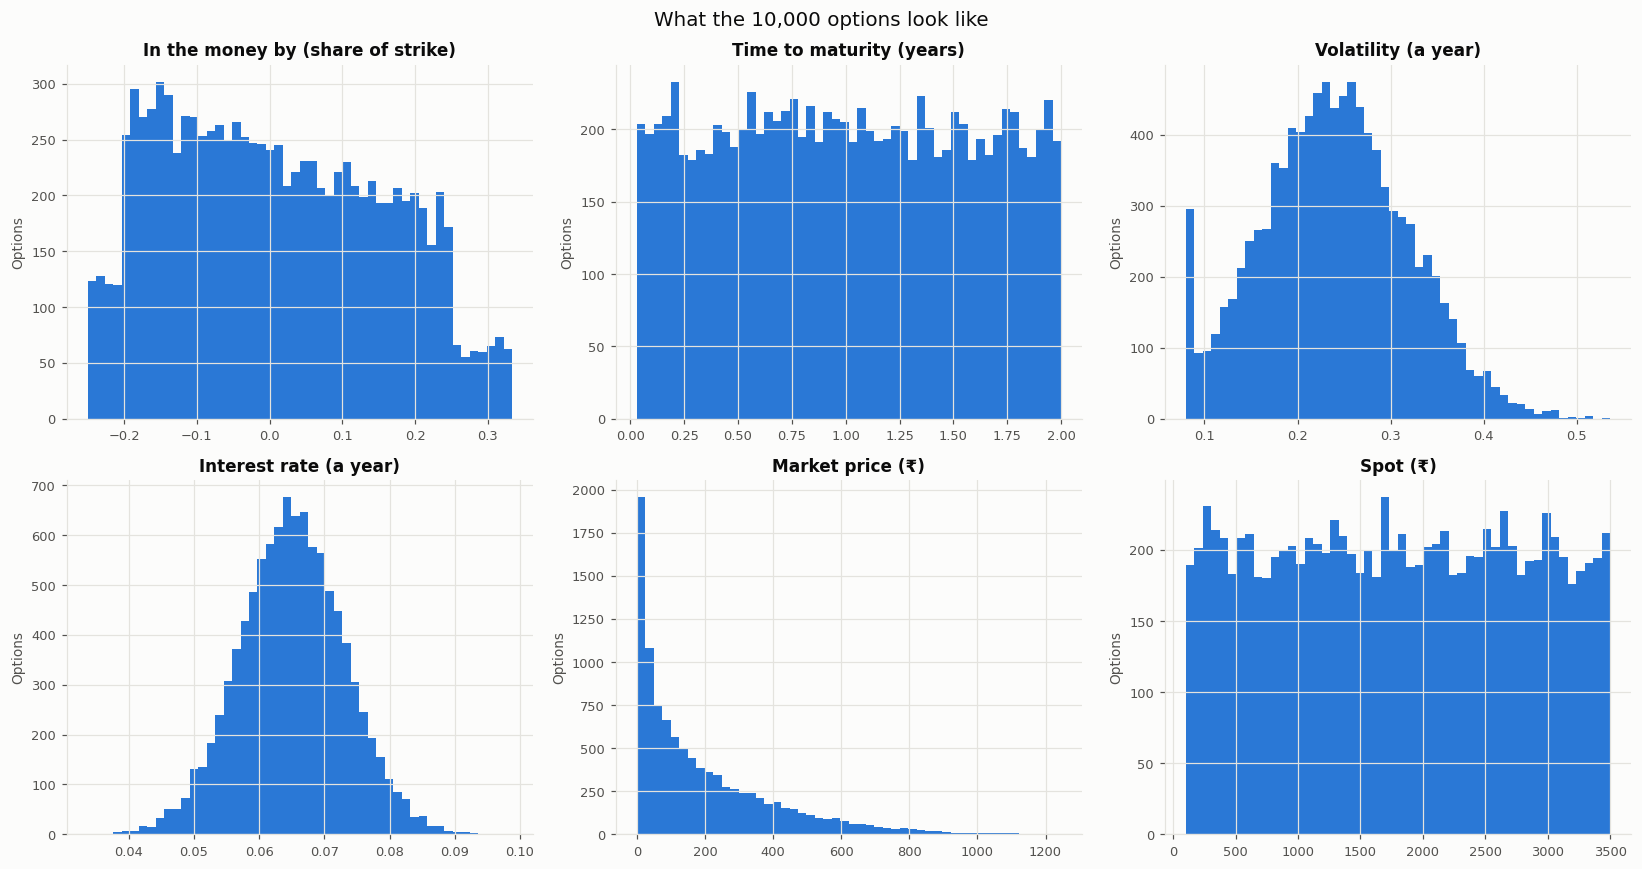

Our BS vs the file's BS: largest difference ₹0.27, average ₹0.025, 43.5% within 1 paisa → the formula matches (differences are rounding)
Worked example: spot ₹1,500, strike ₹1,550, 0.5 years, volatility 25%, rate 7%, call → ₹107.20
First option in the file: MARUTI Put, strike ₹2,235.17, spot ₹1,863.14, 0.63 years, volatility 19.5%, rate 7.43% → our BS ₹302.61 (file ₹302.60); market ₹320.43


,Measure,Value,95% range,Meaning
0,Average gap size (MAE),₹5.84,₹5.69 to ₹6.01,"How far BS is from the market, on average, per..."
1,"Typical gap, big misses counted extra (RMSE)",₹9.81,₹9.51 to ₹10.14,Higher than MAE → some large misses
2,Bias (average market − BS),₹+0.05,₹-0.14 to ₹+0.25,Range includes 0 → BS is not too high or too l...
3,"Typical gap as % of BS (median |gap|, options ...",3.14%,—,Half the options are closer than this
4,Options within ±5% of BS (≥ ₹1),69%,—,Share close enough for everyday use
5,Options more than 20% from BS (≥ ₹1),6.1%,—,"Large misses, mostly cheap options"
6,Total |gap| as share of book value (one unit e...,3.01%,—,"≈ ₹3.0 lakh per ₹1 crore of options, if each w..."


Gap by price (fifths of BS price):


,BS price from (₹),to (₹),MAE (₹),Bias (₹),Median |gap| (% of BS)
Price fifth,,,,,
1 (cheapest),0.0000,25.8273,1.4800,0.1533,0.1287
2,25.8376,81.9635,2.1143,-0.0442,0.0351
3,81.9960,177.0380,3.9147,0.0043,0.0270
4,177.1223,342.8446,7.2773,0.0422,0.0248
5 (dearest),342.9813,1188.4225,14.4238,0.1091,0.0232


Shape of the gap: skew +0.26 (0 = symmetric), extra tail weight (kurtosis) 9.7 (0 = bell curve) → mostly small, a few large


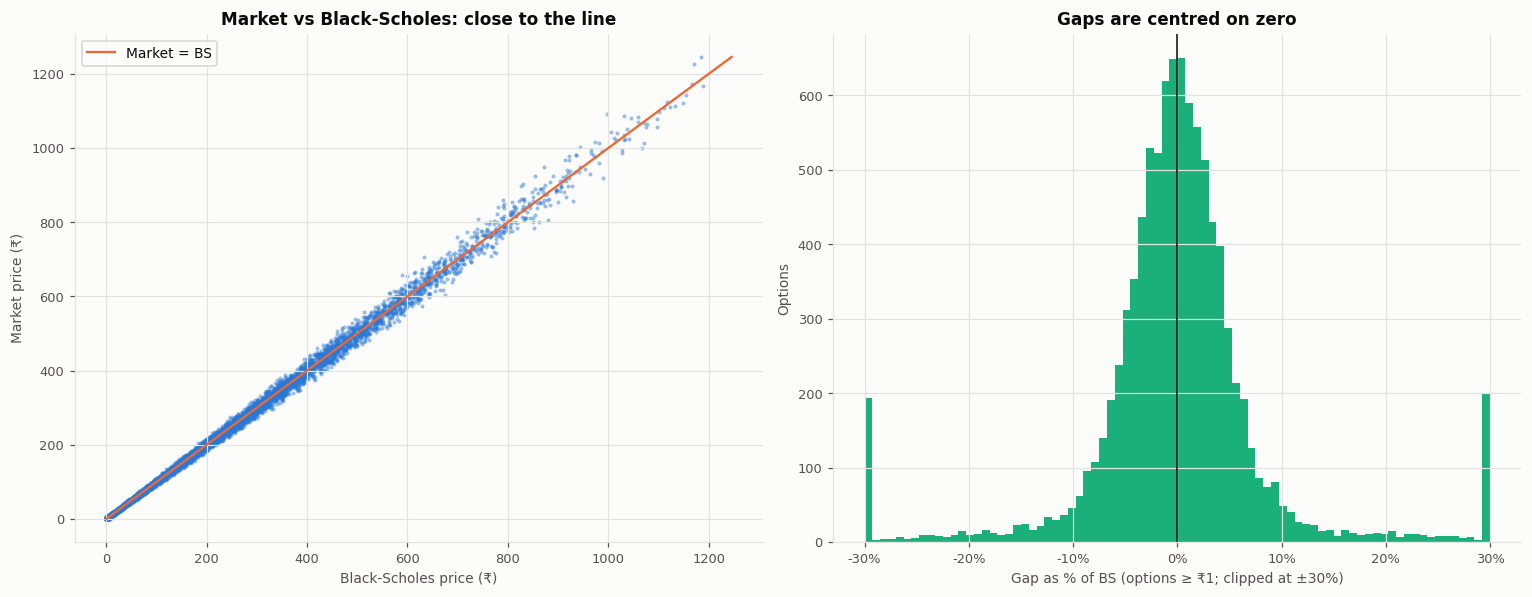

Line for each test: 0.0042


,Breakdown,Groups,p: direction differs,p: size differs,Passes the line (direction),Passes the line (size)
0,Call or put,2,0.2362,0.0000,No,Yes
1,Moneyness,5,0.5673,0.0000,No,Yes
2,Maturity,4,0.1771,0.0000,No,Yes
3,Volatility,5,0.3158,0.0000,No,Yes
4,Price fifth,5,0.4914,0.0000,No,Yes
5,Stock,15,0.5159,0.4928,No,No


,Breakdown,Group,Options,MAE (₹),Bias (₹),Median |gap| (% of BS),Average gap (% of BS),Market above BS
0,Call or put,Call,4945,7.1864,-0.0856,0.0285,-0.0024,0.4918
1,Call or put,Put,5055,4.5269,0.1885,0.0349,0.0087,0.5092
2,Moneyness,Far out of the money (< −10%),2931,2.7224,0.1191,0.0453,0.0072,0.5125
3,Moneyness,Out of the money (−10% to −2%),1740,3.9700,-0.1280,0.0371,0.0057,0.4822
4,Moneyness,At the money (±2%),832,5.4207,-0.3165,0.0312,0.0028,0.4748
5,Moneyness,In the money (2% to 10%),1495,6.3953,0.0854,0.0275,-0.0011,0.5104
6,Moneyness,Far in the money (> 10%),3002,9.8142,0.1795,0.0243,0.0003,0.5020
7,Maturity,Under 3 months,1154,3.7922,-0.1005,0.0367,0.0092,0.5147
8,Maturity,3–6 months,1198,4.5096,-0.2634,0.0349,-0.0062,0.4766
9,Maturity,6–12 months,2647,5.2827,-0.0556,0.0317,0.0002,0.4998


Links between each input and the gap (−1 to +1; near 0 = no pattern):


,Input,Rank link with gap %,Rank link with |gap %|
0,In the money by,0.007,-0.275
1,Time_to_Maturity,0.017,-0.080
2,Volatility,0.003,-0.110
3,Interest_Rate,-0.003,0.012
4,Spot,0.005,-0.171
5,Strike,0.008,-0.187
6,BS price,0.014,-0.411


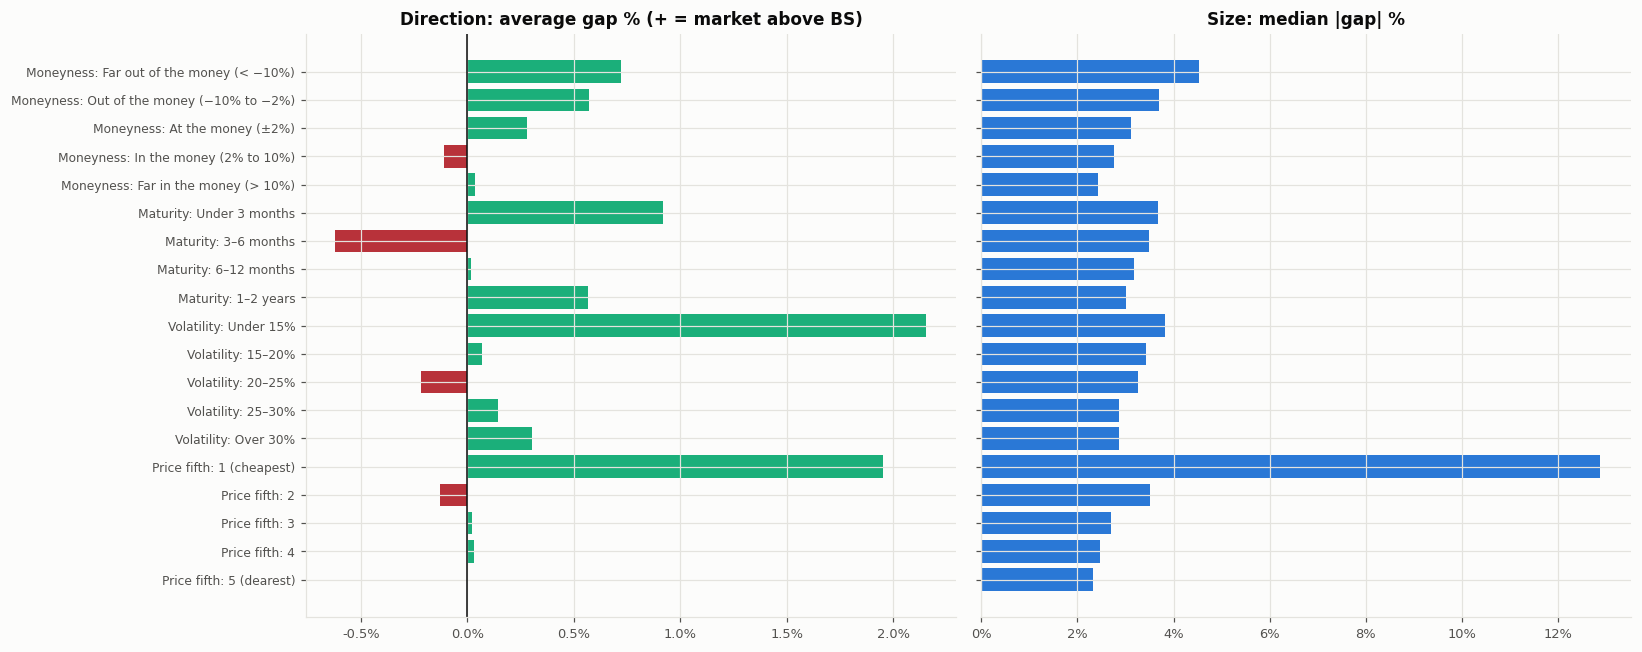

Market prices below the floor: 359 (3.6%); BS prices below the floor: 0
Below intrinsic value (not an error for European options): 1185


,Option_Type,Moneyness band,Options,Average shortfall below floor (₹),Average gap vs BS (₹)
0,Call,In the money (2% to 10%),24,4.14,-8.44
1,Call,Far in the money (> 10%),262,9.46,-13.82
2,Put,In the money (2% to 10%),4,1.74,-4.04
3,Put,Far in the money (> 10%),69,7.67,-9.98


Average gap of flagged options: MAE ₹12.62 vs ₹5.59 for the rest
They are options worth little more than their floor (deep in the money, little time value), where a normal-sized negative gap pushes the price under the floor.


,Underlying,Options,Book value at market (₹),Stock-equivalent exposure (₹),Net delta (shares),Vega: ₹ for volatility +1 point,Theta: ₹ per day,"If the stock falls 5% (₹, delta + gamma)","If the stock falls 5% (₹, exact)","If the stock rises 5% (₹, exact)"
0,AXISBANK,657.0,128918.2,165993.8,100.5,3413.1,-135.0,-6219.5,-6168.6,10320.2
1,BHARTIARTL,665.0,123902.3,139310.0,80.8,3233.0,-135.4,-4860.6,-4819.5,9031.2
2,HDFCBANK,668.0,135161.2,192184.6,116.0,3390.9,-141.8,-7522.5,-7430.8,11602.7
3,HINDUNILVR,695.0,140141.6,159483.8,83.4,3553.3,-145.6,-5788.0,-5689.5,10068.0
4,ICICIBANK,698.0,133314.9,137763.1,89.3,3528.5,-133.6,-4712.4,-4658.7,9003.0
5,INFY,702.0,135945.6,167623.7,97.7,3562.9,-151.5,-6071.7,-5973.0,10602.2
6,ITC,643.0,127559.9,168373.7,101.2,3234.9,-130.6,-6366.6,-6322.2,10434.0
7,KOTAKBANK,676.0,128613.7,128479.0,72.5,3503.6,-135.5,-4251.6,-4157.8,8512.9
8,LT,639.0,125880.7,198453.7,98.3,3290.2,-141.8,-7877.7,-7805.0,11885.6
9,MARUTI,671.0,124289.2,167002.5,86.6,3307.2,-150.0,-6217.8,-6170.7,10417.5


Whole book (one unit each): worth ₹1,939,537; behaves like ₹2,257,447 of stock; volatility +1 point → ₹+50,463; each day → ₹-2,068; all stocks −5% → ₹-79,948 (delta + gamma estimate ₹-80,935)
The book's biggest risks (one unit of each option, OWNED):


,Scenario,Change in book value (₹)
0,Stocks −5%,-79948.0
1,Stocks +5%,143768.0
2,Volatility −5 points (markets calm down),-239685.0
3,Volatility +5 points (markets get jumpier),261843.0
4,Stocks −5% and volatility +5 points (typical s...,180001.0
5,Stocks +5% and volatility −5 points (calm rally),-90075.0


Volatility falling 5 points costs more than stocks falling 5%: volatility is the book's biggest risk. If NovaFin had written (sold) these options instead, every sign flips (Task 2 checks both).
Calls vs puts (calls add stock exposure, puts subtract it):


,Options,Stock-equivalent exposure (₹),Vega: ₹ per +1 point,Theta: ₹ per day
Option_Type,,,,
Call,4945,5528670.0,24998.0,-1746.0
Put,5055,-3271223.0,25465.0,-322.0


Book at BS ₹1,939,008 vs at market ₹1,939,537: net difference ₹+530 (+0.027%); option by option the gaps total ₹58,420


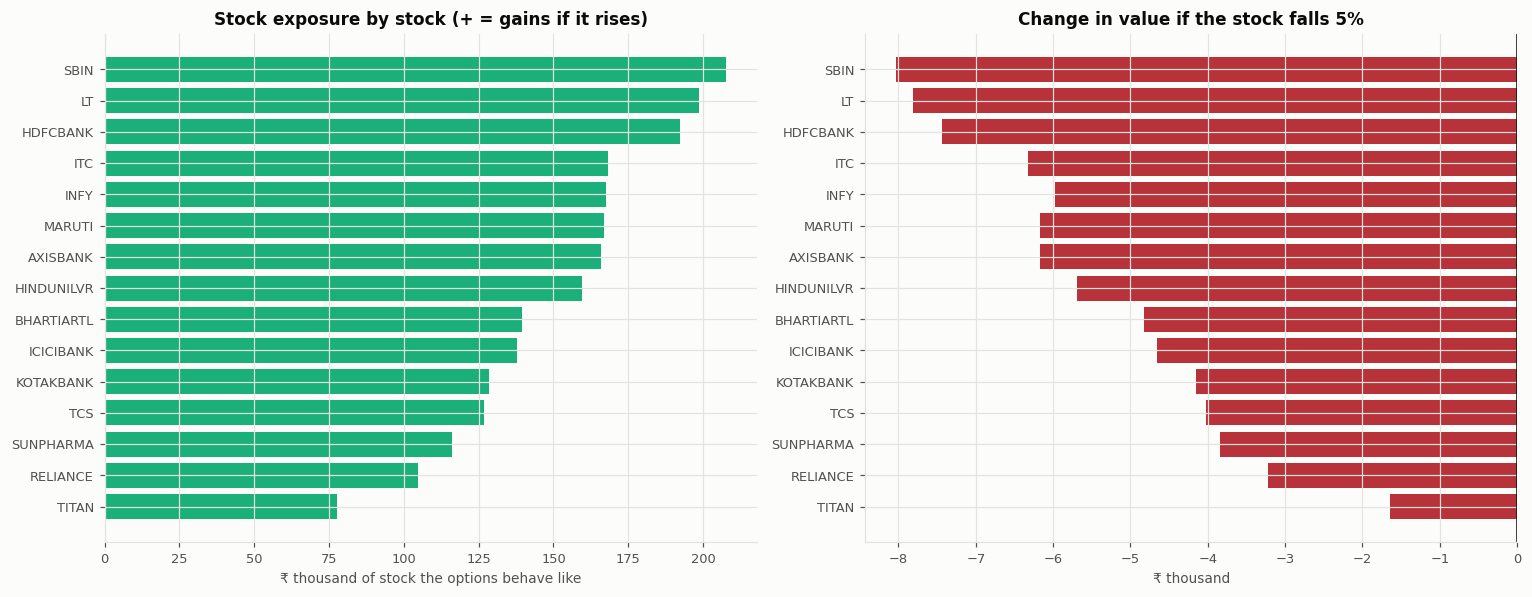

R² of the % gap from the inputs (unseen options): -0.1044; shuffled versions: -0.0204 (range -0.0260 to -0.0132)
Average |gap %|: BS alone 6.61%; BS + learned correction 6.85%


,What Task 1 found,What it means,Consequence for Task 2 decisions
0,"The gap has no direction (bias ₹+0.05, range i...",BS already captures everything the 5 inputs ca...,"Task 2's honest expectation: ML can match BS, ..."
1,A flexible model explains R² = -0.1044 of the ...,No learnable pattern beyond BS,The 'BS + correction' (hybrid) set-up (M8-02) ...
2,"MAE ₹5.84, growing with price (₹1.48 cheapest ...","Errors must be compared in ₹ and in %, by pric...","Task 2 reports MAE/RMSE in ₹ and % (≥ ₹1), ove..."
3,359 market prices below the no-arbitrage floor,Data errors that no model should learn,"Decide in Task 2: train without them, report w..."
4,"Book behaves like ₹2,257,447 of stock; −5% in ...",Exposure is measurable from BS Greeks,Task 2: decide whether ML prices change the he...
5,"Volatility −5 points → ₹-239,685, more than a ...",Volatility is the biggest risk; shares can't h...,Task 2: compare hedges that include options (v...
6,Spot and volatility differ for every option on...,The stock label is not a real single stock,Task 2: size hedges in ₹; treat any hedge resu...
7,Whether NovaFin owns or wrote the options is n...,Every risk's sign depends on it,Task 2: main view owned (M8-05); check the wri...


Example: MARUTI put (right to sell) at strike ₹2,235.17 with the stock at ₹1,863.14 (20% in the money), 0.63 years left, volatility 20%: Black-Scholes says ₹302.61, the market pays ₹320.43, ₹17.82 (5.9%) above the formula. If the stock rises ₹1 this option changes by ₹-0.79; it gains ₹0.18 a day as time passes.
Saved to module_08_derivatives/outputs/task1
['01_eda_inputs.png', '02_market_vs_bs.png', '03_where_bs_misses.png', '04_book_risk.png', 'FINAL_M8_T1_bs_benchmark.csv', 'book_risk_by_stock.csv', 'book_stress_scenarios.csv', 'gap_by_segment.csv', 'key_numbers.json', 'segment_tests.csv', 'spot_check_by_stock.csv']


In [3]:
%run notebooks/m08_task1_bs_benchmark.ipynb

## 2. Task 2 — ML pricing
Runs `notebooks/m08_task2_ml_pricing.ipynb` (about 2 minutes):
- eight ML set-ups (direct and hybrid × four models), chosen on the training options;
- the test, used once: ML vs Black-Scholes in ₹ and %, with 95% ranges, by group, and a luck test;
- the delta hedge: the book's ₹ change for ±1%, ±5%, ±10% moves, unhedged and hedged;
- saves `outputs/task2/FINAL_M8_T2_ml_pricing.csv`.

From Task 1: BS average gap ₹5.84, bias ₹+0.05, 359 impossible prices, learned-correction R² -0.10
Training options: 8,000 → 7,709 after removing 291 impossible prices; test options: 2,000 (of which 68 impossible)


,Set-up,Model,MAE on held-out folds (₹),Spread across folds (₹),MAE on its own training folds (₹),vs BS (₹; + = worse than BS)
0,Direct,Linear regression,112.022,3.514,111.836,106.486
1,Direct,Random forest,9.577,0.270,6.280,4.042
2,Direct,LightGBM,8.016,0.305,5.298,2.481
3,Direct,Neural network,10.281,0.432,8.312,4.746
4,Hybrid,Linear regression,5.591,0.145,5.587,0.056
5,Hybrid,Random forest,5.730,0.149,3.708,0.195
6,Hybrid,LightGBM,5.936,0.122,4.124,0.401
7,Hybrid,Neural network,10.973,0.915,8.474,5.438
8,Formula,Black-Scholes,5.535,0.146,5.535,0.000


,Set-up,Model,MAE on its own training folds (₹),MAE on held-out folds (₹),Overfitting gap (₹)
0,Direct,Linear regression,111.836,112.022,0.186
1,Direct,Random forest,6.280,9.577,3.298
2,Direct,LightGBM,5.298,8.016,2.718
3,Direct,Neural network,8.312,10.281,1.969
4,Hybrid,Linear regression,5.587,5.591,0.004
5,Hybrid,Random forest,3.708,5.730,2.023
6,Hybrid,LightGBM,4.124,5.936,1.812
7,Hybrid,Neural network,8.474,10.973,2.499
8,Formula,Black-Scholes,5.535,5.535,0.000


,Choice,Held-out MAE (₹),vs BS,Learned noise (overfitting gap),Explainable?,Needs BS?
0,Direct: LightGBM,8.02,+2.48 ₹ (worse),₹2.72,Hard: hundreds of trees,No
1,Hybrid: Linear regression,5.59,+0.06 ₹ (worse),₹0.00,Easy: one weight per input,Yes: adds to BS
2,Black-Scholes (benchmark),5.54,—,None: nothing is learned,Yes: a formula every desk knows,—


Going to the test: {'Direct': 'LightGBM', 'Hybrid': 'Linear regression'}


,Test set,Pricer,MAE (₹),RMSE (₹),Bias (₹),Median |gap| (% of price),₹ saved vs BS per option,95% range,Better than BS?
0,All test options,Black-Scholes,6.0721,10.1465,-0.0489,0.0329,NaN,NaN,NaN
1,All test options,Direct ML (LightGBM),8.4798,13.5856,-0.6776,0.0450,-2.4077,₹-2.71 to ₹-2.09,No: worse
2,All test options,Hybrid ML (Linear regression),6.2207,10.3500,-0.7699,0.0329,-0.1485,₹-0.23 to ₹-0.07,No: worse
3,Without impossible prices,Black-Scholes,5.8067,9.7094,0.4285,0.0327,NaN,NaN,NaN
4,Without impossible prices,Direct ML (LightGBM),8.1334,13.0996,-0.0874,0.0451,-2.3266,₹-2.64 to ₹-2.02,No: worse
5,Without impossible prices,Hybrid ML (Linear regression),5.8299,9.6521,-0.1873,0.0323,-0.0232,₹-0.10 to ₹+0.06,No: no clear difference


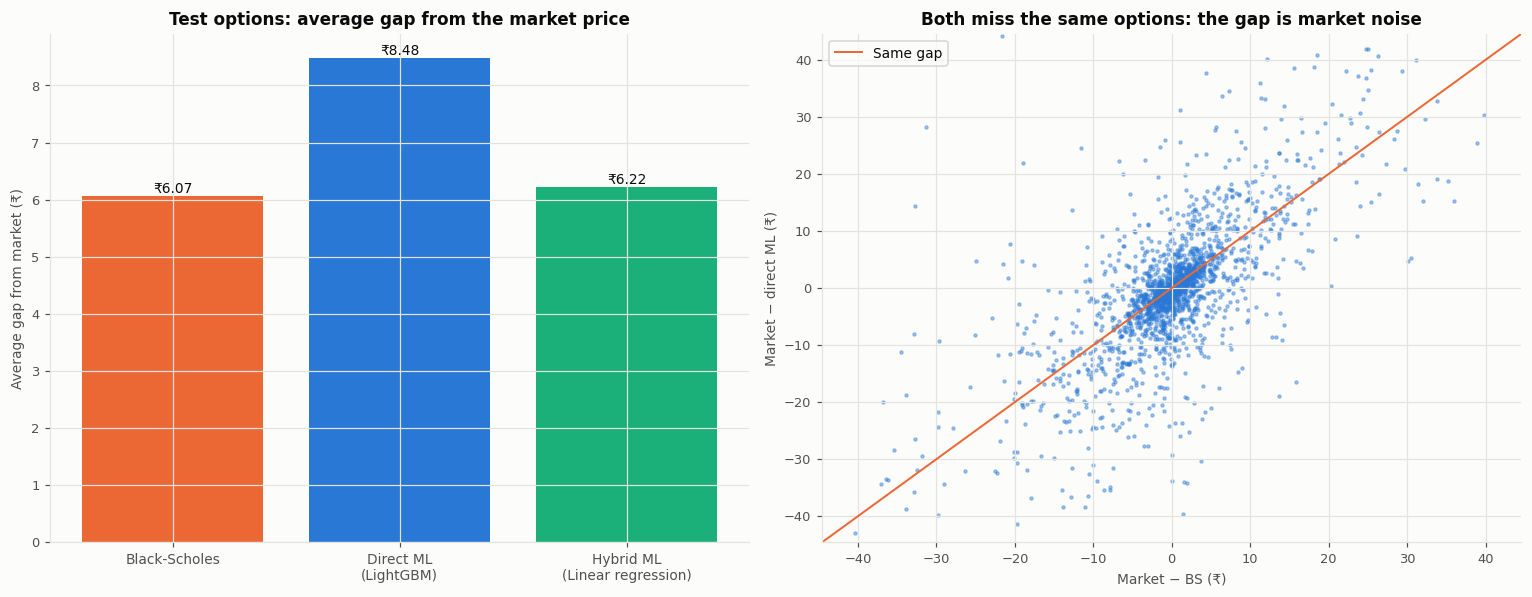

Link between the BS gap and the direct-ML gap on the same options: 0.73 (1 = they miss identically)


,Breakdown,Group,Options,MAE (₹): Black-Scholes,MAE (₹): Direct ML (LightGBM),MAE (₹): Hybrid ML (Linear regression),Best
0,Price fifth,1 (cheapest),400,1.558,2.532,1.792,Black-Scholes
1,Price fifth,2,400,2.111,3.433,2.151,Black-Scholes
2,Price fifth,3,400,4.168,6.276,4.293,Black-Scholes
3,Price fifth,4,400,7.422,11.329,7.433,Black-Scholes
4,Price fifth,5 (dearest),400,15.102,18.829,15.434,Black-Scholes
5,Moneyness band,At the money (±2%),167,6.138,8.428,6.167,Black-Scholes
6,Moneyness band,Far in the money (> 10%),612,9.874,12.888,10.160,Black-Scholes
7,Moneyness band,Far out of the money (< −10%),599,2.915,4.886,3.098,Black-Scholes
8,Moneyness band,In the money (2% to 10%),291,6.949,9.590,6.968,Black-Scholes
9,Moneyness band,Out of the money (−10% to −2%),331,3.953,5.883,3.958,Black-Scholes


Groups where BS is best: 12 of 12


,Stock,Test options,MAE (₹): Black-Scholes,MAE (₹): Direct ML (LightGBM),MAE (₹): Hybrid ML (Linear regression),Best,Best ML vs BS (₹; + = ML closer)
0,AXISBANK,127.0,6.54,9.44,6.55,Black-Scholes,-0.02
1,BHARTIARTL,140.0,5.40,7.44,5.53,Black-Scholes,-0.13
2,HDFCBANK,142.0,6.02,9.17,6.43,Black-Scholes,-0.41
3,HINDUNILVR,135.0,6.62,8.53,6.92,Black-Scholes,-0.30
4,ICICIBANK,147.0,6.40,9.08,6.51,Black-Scholes,-0.12
5,INFY,131.0,4.95,7.17,5.08,Black-Scholes,-0.13
6,ITC,119.0,4.84,7.25,5.05,Black-Scholes,-0.21
7,KOTAKBANK,148.0,5.66,10.24,5.89,Black-Scholes,-0.23
8,LT,114.0,6.90,7.80,7.22,Black-Scholes,-0.32
9,MARUTI,133.0,6.06,7.41,6.08,Black-Scholes,-0.01


BS best in 13 of 15 stocks; where ML is best, by at most ₹0.17 per option, on about 130 options: within noise (Task 1: the stock makes no difference, p 0.49)


Hybrid's test MAE ₹6.221; with shuffled corrections ₹6.128 (range ₹6.112–₹6.152); BS alone ₹6.072; p = 1.000 (small p = the correction learned something real)


,Input,In plain words,Worsening when shuffled (₹ per option)
0,S/K,How far the stock is from the strike,126.11
5,Is call,Call or put,124.09
6,Vol x sqrt(T),Total expected swing until the end,43.76
1,ln(S/K),"Same, on a log scale",16.01
2,Time_to_Maturity,Time left,15.93
3,Volatility,How much the stock swings,7.84
4,Interest_Rate,Interest rate,2.50


These are exactly Black-Scholes' own inputs: the direct model has re-learned the formula, not found anything new.


Change in the book's value (₹) in each scenario:


,Stocks move,Volatility change (points),A. No hedge,B. Delta hedge,C. Delta + half vega hedge,D. Delta + full vega hedge
0,-10%,-5,-320084.0,-94339.0,-29159.0,36021.0
1,-10%,+0,-90621.0,135124.0,78158.0,21192.0
2,-10%,+5,160217.0,385962.0,206450.0,26939.0
3,-5%,-5,-318292.0,-205419.0,-91662.0,22096.0
4,-5%,+0,-79948.0,32925.0,19169.0,5413.0
5,-5%,+5,180001.0,292873.0,151892.0,10911.0
6,-1%,-5,-261278.0,-238704.0,-113088.0,12528.0
7,-1%,+0,-21289.0,1286.0,753.0,220.0
8,-1%,+5,240722.0,263297.0,135526.0,7755.0
9,+0%,-5,-239685.0,-239685.0,-114582.0,10520.0


,Choice,Worst result (₹),Worst scenario,Best result (₹),"Typical swing (₹, average size of change)",Scenarios that lose,Shares to trade (₹),Calls to sell (units),Premium received for calls sold (₹),Total trading (₹: shares + calls sold),Total trading ÷ book value,Upfront trading cost (₹),Time decay (₹ a day),Volatility sensitivity left (₹ per point)
0,A. No hedge,-320084.0,"stocks -10%, volatility -5 points",591833.0,209233.0,9,0.0,-0.0,0.0,0.0,0.0,0.0,-2068.0,50463.0
1,B. Delta hedge,-239685.0,"stocks +0%, volatility -5 points",385962.0,179162.0,7,2257447.0,-0.0,0.0,2257447.0,1.0,2257.0,-2068.0,50463.0
2,C. Delta + half vega hedge,-114582.0,"stocks +0%, volatility -5 points",206450.0,91420.0,7,2196997.0,3813.0,867022.0,3064019.0,2.0,10867.0,-603.0,25232.0
3,D. Delta + full vega hedge,0.0,"stocks +0%, volatility +0 points",42593.0,13565.0,0,6651441.0,7625.0,1734045.0,8385485.0,4.0,23992.0,862.0,0.0


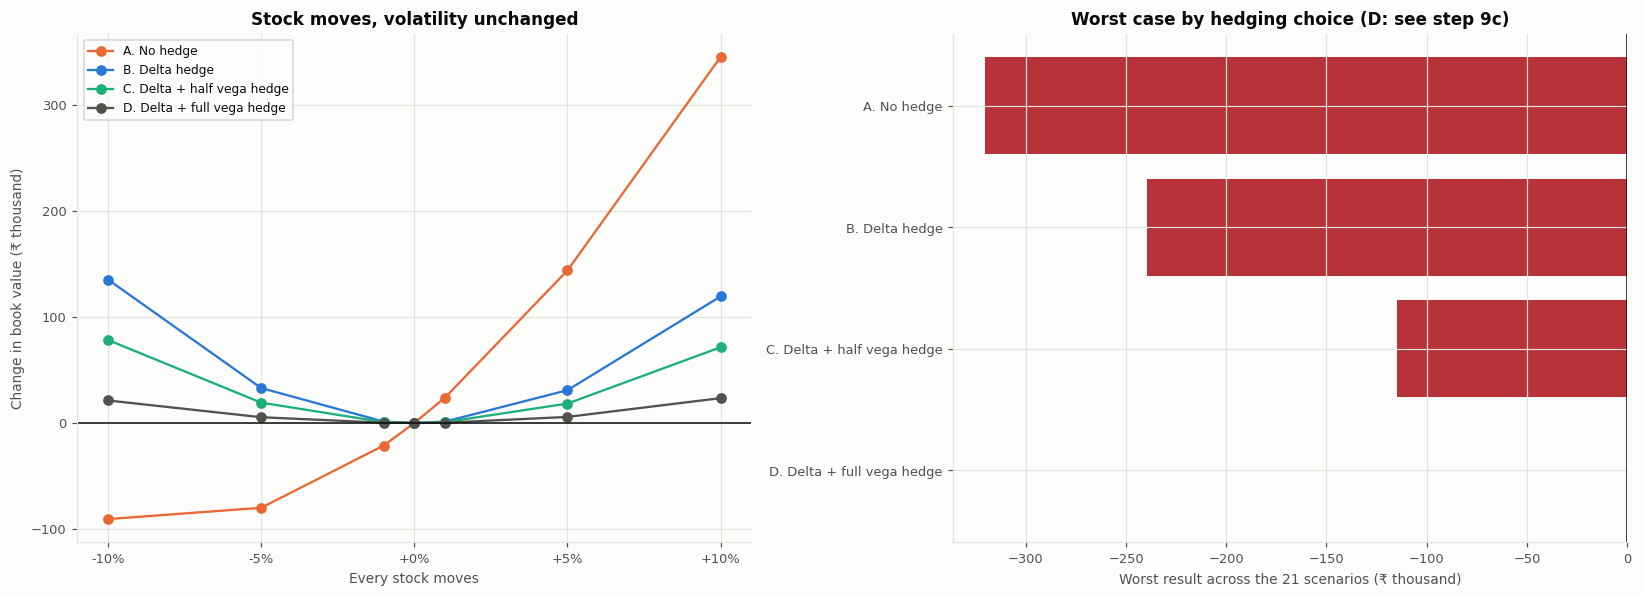

Check — stocks -5%, volatility +0 points: estimate ₹-80,935, exact ₹-79,948
Check — stocks +0%, volatility -5 points: estimate ₹-252,316, exact ₹-239,685
Check — stocks -5%, volatility +5 points: estimate ₹+171,381, exact ₹+180,001


OWNED book (main view, M8-05):


,Choice,Chance of a losing day,Average day (₹),1-in-20 bad day: loss (₹),1-in-100 bad day: loss (₹),Chance of a losing month,1-in-20 bad month: loss (₹)
0,A. No hedge,0.491,1001.575,71903.728,102738.386,0.457,316311.483
1,B. Delta hedge,0.495,1057.472,81275.101,114853.641,0.467,357559.127
2,C. Delta + half vega hedge,0.485,1212.226,39928.395,56653.453,0.418,164504.247
3,D. Delta + full vega hedge,0.000,1366.981,-1041.256,-987.433,0.000,-26450.418


Check — if NovaFin had WRITTEN (sold) these options (M8-20): every risk flips


,Choice,Chance of a losing day,Average day (₹),1-in-20 bad day: loss (₹),1-in-100 bad day: loss (₹),Chance of a losing month,1-in-20 bad month: loss (₹)
0,A. No hedge,0.509,-1001.575,74299.029,104540.393,0.543,363312.537
1,B. Delta hedge,0.505,-1057.472,84606.641,120195.048,0.533,404373.176
2,C. Delta + half vega hedge,0.515,-1212.226,43023.451,60949.431,0.582,216219.106
3,D. Delta + full vega hedge,1.000,-1366.981,2028.056,2653.935,1.000,31446.176


Check — 1-in-100 bad-day loss (₹) if volatility moves less or more than assumed:


... (4 outputs left out)

,Board's limit: most it accepts losing on a 1-in-100 bad day,Choice with the least trading within it
0,"2% of the book (₹38,791)","None of A–C (would need a fuller vega hedge, n..."
1,"3% of the book (₹58,186)",C. Delta + half vega hedge
2,"4% of the book (₹77,581)",C. Delta + half vega hedge
3,"5% of the book (₹96,977)",C. Delta + half vega hedge
4,"6% of the book (₹116,372)",A. No hedge


Recommended at a 4% limit (₹77,581): C. Delta + half vega hedge


,Stock,Options,Book value (₹),Stock-equivalent exposure (₹),Volatility sensitivity (₹ per point),Time decay (₹ a day),Unhedged: stocks −5% (₹),Unhedged: volatility −5 points (₹),C. Delta + half vega hedge: calls to sell (units),C. Delta + half vega hedge: shares to buy (+) or sell (−) (₹),C. Delta + half vega hedge: worst of the 21 scenarios (₹)
0,AXISBANK,657,128918.0,165994.0,3413.0,-135.0,-6169.0,-16222.0,255.0,134536.0,-7758.0
1,BHARTIARTL,665,123902.0,139310.0,3233.0,-135.0,-4819.0,-15353.0,256.0,145422.0,-7335.0
2,HDFCBANK,668,135161.0,192185.0,3391.0,-142.0,-7431.0,-16048.0,254.0,105674.0,-7633.0
3,HINDUNILVR,695,140142.0,159484.0,3553.0,-146.0,-5690.0,-16915.0,264.0,153492.0,-8099.0
4,ICICIBANK,698,133315.0,137763.0,3529.0,-134.0,-4659.0,-16721.0,265.0,175228.0,-7985.0
5,INFY,702,135946.0,167624.0,3563.0,-151.0,-5973.0,-16953.0,260.0,146889.0,-8120.0
6,ITC,643,127560.0,168374.0,3235.0,-131.0,-6322.0,-15289.0,230.0,118510.0,-7281.0
7,KOTAKBANK,676,128614.0,128479.0,3504.0,-136.0,-4158.0,-16712.0,268.0,181433.0,-8028.0
8,LT,639,125881.0,198454.0,3290.0,-142.0,-7805.0,-15537.0,241.0,92061.0,-7381.0
9,MARUTI,671,124289.0,167003.0,3307.0,-150.0,-6171.0,-15761.0,257.0,124039.0,-7562.0


Share amounts are in ₹: options on the same stock carry different spot prices in this data (Task 1), so share counts are not meaningful.


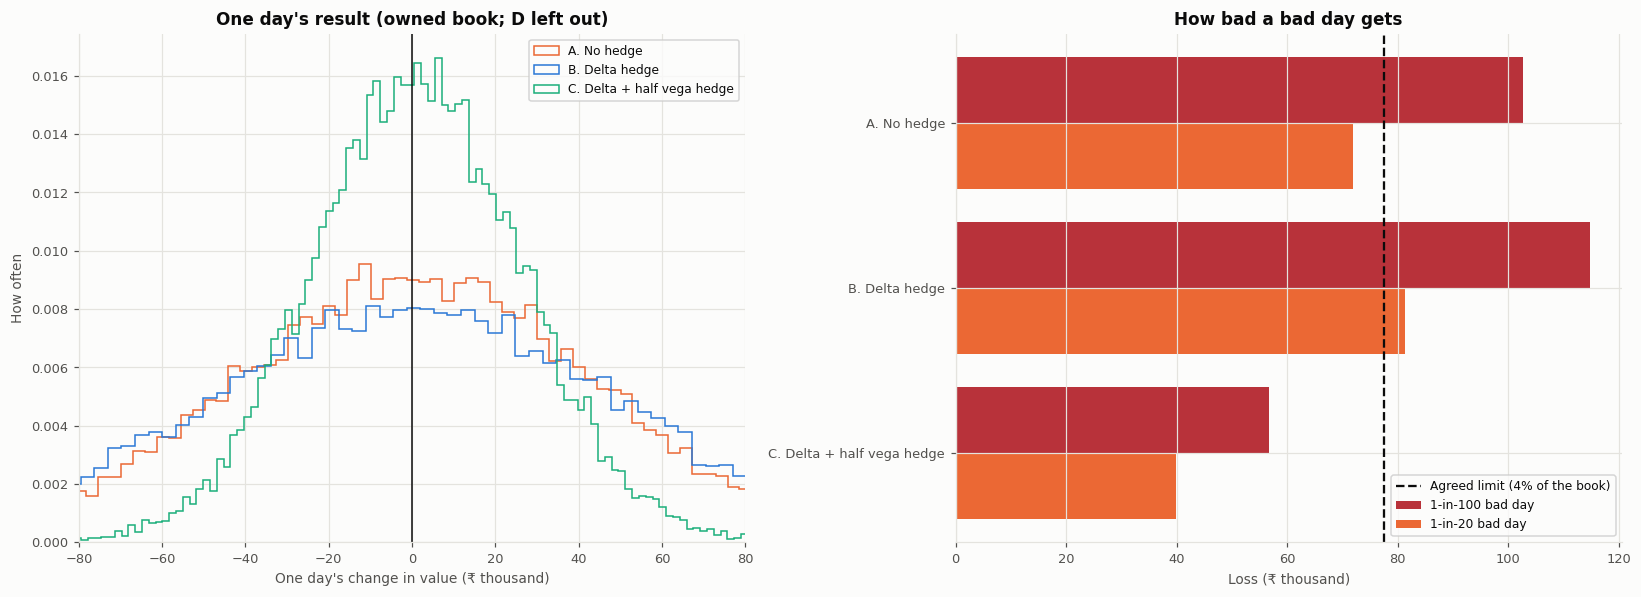

,Floor,Priced at,Cost a year (₹ crore per ₹100 crore),Normal year: equity return after the cost (% a year),Stocks -10%: result (₹ crore per ₹100 crore),Stocks -20%: result (₹ crore per ₹100 crore),Stocks -30%: result (₹ crore per ₹100 crore)
0,100%,Module 6 swing (19.4%),4.67,10.93,-4.67,-4.67,-4.67
1,100%,Check: puts priced dearer (25.0%),6.75,8.85,-6.75,-6.75,-6.75
2,90%,Module 6 swing (19.4%),1.81,13.79,-11.81,-11.81,-11.81
3,90%,Check: puts priced dearer (25.0%),3.33,12.27,-13.33,-13.33,-13.33
4,80%,Module 6 swing (19.4%),0.49,15.11,-10.49,-20.49,-20.49
5,80%,Check: puts priced dearer (25.0%),1.31,14.29,-11.31,-21.31,-21.31


Unprotected, a 20% crash costs ₹20 crore per ₹100 crore. A 90% floor costs ₹1.81 crore a year, cuts that to ₹11.8 crore, and leaves a normal year at 13.8% instead of 15.6%.
Link to Module 7: equal-weight turnover is 0.78× a year, so timing those orders saves about 0.010% a year of the equity money (₹1.03 lakh per ₹100 crore): real but small.


,Category,Return per ₹ deployed (% a year),Bad-year result per ₹ (% a year)
0,Derivatives hedging: protect equity money (100...,-4.67,-4.67
1,Derivatives hedging: protect equity money (90%...,-1.81,-11.81
2,Derivatives hedging: protect equity money (80%...,-0.49,-20.49
3,Derivatives hedging: the option book (choice C),-2.91,-2.92


,Pricer,Average gap per option (₹),"Across the 10,000-option book (₹ lakh)",Per ₹1 crore of options (₹ lakh),Difference vs BS across the book (₹)
0,Black-Scholes,6.07,0.61,3.08,0.00
1,Direct ML (LightGBM),8.48,0.85,4.30,-24076.70
2,Hybrid ML (Linear regression),6.22,0.62,3.15,-1485.12


Best ML (Hybrid ML (Linear regression)) vs BS across the book: ₹-1,485 (+ = ML closer). Hedging (step 9c): 1-in-100 bad day unhedged ₹102,738; with C. Delta + half vega hedge ₹56,653.


Closest to market on the test: {'Black-Scholes': 751, 'Direct ML': 643, 'Hybrid ML': 606}
Example: INFY call, strike ₹1,178.84, stock ₹1,552.56, 1.77 years: the market pays ₹467.16; Black-Scholes says ₹499.99 (off by ₹32.83), direct ML ₹502.98 (off by ₹35.82), hybrid ML ₹505.35 (off by ₹38.19). Closest: Black-Scholes. The market price is below the lowest logical price, so it is likely a data error.
Saved to module_08_derivatives/outputs/task2
['01_ml_vs_bs_test.png', '02_hedging_choices.png', '03_hedge_loss_chances.png', 'FINAL_M8_T2_ml_pricing.csv', 'hedge_by_stock.csv', 'hedge_loss_chances.csv', 'hedge_loss_chances_written_book.csv', 'hedge_running.csv', 'hedge_scenarios.csv', 'hedge_vol_sensitivity.csv', 'hedging_choice_rule.csv', 'hedging_choices.csv', 'key_numbers.json', 'model_comparison.csv', 'model_drivers.csv', 'module9_inputs.csv', 'protect_equity_money.csv', 'test_by_segment.csv', 'test_by_stock.csv']


In [4]:
%run notebooks/m08_task2_ml_pricing.ipynb

## Final output workbook
Builds **`outputs/FINAL_M8_module_output.xlsx`**: the one file to open for this module's results (project decision P-21).
- Tabs: Read me (with a column guide) · Key numbers · Board actions · each task's final file · hedge scenarios · Hand-off to Module 9 · Decisions · Evidence index.
- Every hand-off figure is computed from the task tabs' rows, and each row says which tab, column(s) and recipe it comes from.

In [5]:
%run helpers/m08_final_output.py

Saved: FINAL_M8_module_output.xlsx
                                          Figure                                                                                                                                                                                                                                                                                                                                                                                                                       Value                               Unit
Does ML price options better than Black-Scholes?                                                                                                                                                                                                                                                                                                                                                                           No: BS is closest to the market on unseen options         